# A/B Test Analysis: Checkout Page Redesign

**Goal:** find out whether a redesigned checkout page (**treatment**) converts more visitors into buyers than the current page (**control**).

- **Primary metric:** conversion rate (share of users who bought)
- **Secondary metric:** revenue per user
- **Hypotheses:** H0: conversion rate is the same in both groups. H1: conversion rates differ.
- **Significance level:** α = 0.05

**Workflow:**
1. Data collection (API, Python I/O)
2. Data cleaning (Pandas)
3. Data preprocessing (NumPy)
4. Data visualization (Matplotlib, Seaborn)
5. Hypothesis testing (SciPy)

*Note: start the data API with `python serve_data.py` in a separate terminal before running Section 1. If it is not running, the notebook loads `raw_ab_test.csv` instead.*

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

Path("data").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)
ALPHA = 0.05
COLORS = {"control": "#4C72B0", "treatment": "#DD8452"}

## 1. Data Collection (API + Python I/O)

The experiment data is requested from a local API. The raw response is saved to a JSON file so the pull can be reproduced, then loaded into a DataFrame.

In [2]:
API_URL = "http://127.0.0.1:8000/api/ab_test"

try:
    response = requests.get(API_URL, timeout=10)
    response.raise_for_status()          # raises an error for 4xx / 5xx responses
    records = response.json()
    print(f"Loaded {len(records):,} records from the API")
except requests.RequestException:
    print("API not reachable, loading the local CSV instead")
    records = pd.read_csv("raw_ab_test.csv").to_dict(orient="records")

# Python file I/O: save the raw data
with open("data/raw_ab_test.json", "w") as f:
    json.dump(records, f)

raw = pd.DataFrame(records)
raw.head()

Loaded 10,200 records from the API


,user_id,group,date,device,user_type,time_on_page,converted,revenue
0,10870,treatment,2026-09-13,desktop,returning,90.200,0,0.000
1,4006,control,2026-09-09,desktop,returning,303.000,0,0.000
2,10777,treatment,2026-09-11,mobile,returning,111.600,1,80.330
3,1737,treatment,2026-09-01,mobile,returning,117.700,0,0.000
4,10619,control,2026-09-05,mobile,returning,151.700,0,0.000


## 2. Data Cleaning (Pandas)

### 2.1 Inspect the raw data first

In [3]:
print("Shape:", raw.shape)
print("\nMissing values:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nDuplicate rows:", raw.duplicated().sum())
print("\nGroup labels: ", raw["group"].unique())
print("Device labels:", raw["device"].unique())
raw[["time_on_page", "revenue"]].describe()

Shape: (10200, 8)

Missing values:
device          305
time_on_page    305
dtype: int64

Duplicate rows: 200

Group labels:  <StringArray>
[  'treatment',     'control',   'TREATMENT',     'CONTROL', ' treatment ',
   ' control ',   ' CONTROL ', ' TREATMENT ']
Length: 8, dtype: str
Device labels: <StringArray>
['desktop', 'mobile', 'tablet', nan, 'Mobile', 'Desktop', 'Tablet']
Length: 7, dtype: str


,time_on_page,revenue
count,"9,895.000","10,200.000"
mean,172.386,10.763
std,556.604,104.412
min,-314.300,0.000
25%,79.200,0.000
50%,129.500,0.000
75%,199.500,0.000
max,"18,643.200","3,936.780"


**Problems found**
1. `group` has inconsistent labels (`CONTROL`, ` treatment `): extra spaces and mixed case.
2. `device` has mixed case (`Mobile` vs `mobile`) and missing values.
3. Duplicate rows.
4. `time_on_page` has missing values, **negative** values (impossible) and extreme values (a few sessions last hours, likely bots).
5. `revenue` has a few extremely large orders.

### 2.2 Cleaning steps

In [4]:
df = raw.copy()
rows_before = len(df)

# 1. consistent text labels
df["group"] = df["group"].str.strip().str.lower()
df["device"] = df["device"].str.strip().str.lower()
df["device"] = df["device"].fillna("unknown")

# 2. remove duplicate rows
df = df.drop_duplicates()
print(f"Removed {rows_before - len(df)} duplicate rows")

# 3. correct data types
df["date"] = pd.to_datetime(df["date"])

# 4. impossible values -> missing (negative time on page)
n_negative = (df["time_on_page"] < 0).sum()
df.loc[df["time_on_page"] < 0, "time_on_page"] = np.nan
print(f"Set {n_negative} negative time_on_page values to NaN")

# 5. sanity checks
assert df["user_id"].is_unique
assert set(df["group"].unique()) == {"control", "treatment"}
assert df["converted"].isin([0, 1]).all()

df = df.reset_index(drop=True)
print("Clean shape:", df.shape)
df.isna().sum()

Removed 200 duplicate rows
Set 20 negative time_on_page values to NaN
Clean shape: (10000, 8)


user_id           0
group             0
date              0
device            0
user_type         0
time_on_page    319
converted         0
revenue           0
dtype: int64

## 3. Data Preprocessing (NumPy)

Missing values and extreme values are handled with NumPy:
- Fill missing `time_on_page` with the median
- Cap extreme values at the 99th percentile (winsorizing)
- Apply a log transform to reduce skew
- Create a z-score and time buckets

In [5]:
time = df["time_on_page"].to_numpy()
revenue = df["revenue"].to_numpy()

# fill missing time with the median
median_time = np.nanmedian(time)
time = np.where(np.isnan(time), median_time, time)

# cap extreme values at the 99th percentile
time_cap = np.percentile(time, 99)
rev_cap = np.percentile(revenue[revenue > 0], 99)      # percentile among buyers only
print(f"time_on_page cap: {time_cap:,.0f}s  |  revenue cap: ${rev_cap:,.0f}")
print(f"Values capped -> time: {(time > time_cap).sum()}, revenue: {(revenue > rev_cap).sum()}")

time_capped = np.clip(time, 0, time_cap)
revenue_capped = np.clip(revenue, 0, rev_cap)

# new columns
df["time_on_page"] = time_capped
df["revenue_capped"] = revenue_capped
df["log_time"] = np.log1p(time_capped)
df["time_zscore"] = (time_capped - time_capped.mean()) / time_capped.std()
df["time_bucket"] = np.select(
    [time_capped < 60, time_capped < 180, time_capped < 360],
    ["<1 min", "1-3 min", "3-6 min"],
    default="6+ min",
)
df[["time_on_page", "revenue_capped", "log_time", "time_zscore", "time_bucket"]].head()

time_on_page cap: 470s  |  revenue cap: $233
Values capped -> time: 100, revenue: 13


,time_on_page,revenue_capped,log_time,time_zscore,time_bucket
0,90.200,0.000,4.513,-0.636,1-3 min
1,303.000,0.000,5.717,1.662,3-6 min
2,111.600,80.330,4.724,-0.405,1-3 min
3,117.700,0.000,4.777,-0.339,1-3 min
4,151.700,0.000,5.028,0.028,1-3 min


In [6]:
df.to_csv("data/clean_ab_test.csv", index=False)

summary = df.groupby("group").agg(
    users=("user_id", "count"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean"),
    revenue_per_user=("revenue_capped", "mean"),
)
summary

,users,conversions,conversion_rate,revenue_per_user
group,,,,
control,5061,593,0.117,7.428
treatment,4939,661,0.134,8.442


## 4. Data Visualization (Matplotlib & Seaborn)

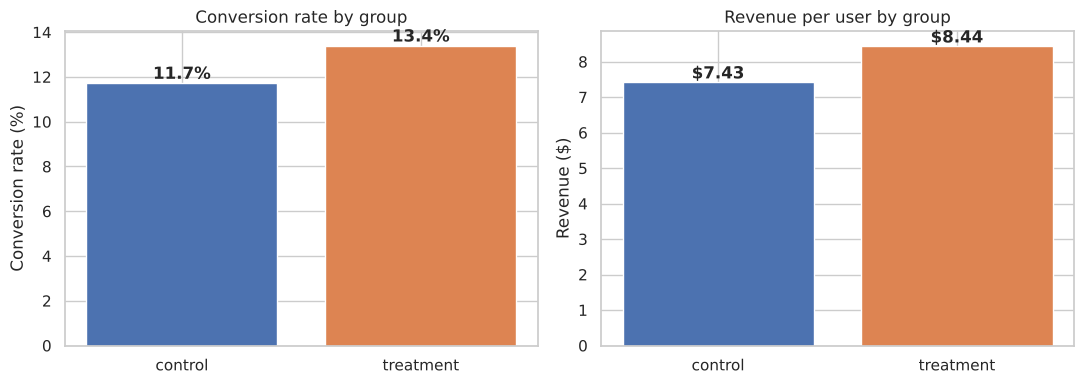

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# conversion rate per group
rates = df.groupby("group")["converted"].mean() * 100
ax[0].bar(rates.index, rates.values, color=[COLORS[g] for g in rates.index])
for i, v in enumerate(rates.values):
    ax[0].text(i, v + 0.2, f"{v:.1f}%", ha="center", fontweight="bold")
ax[0].set_title("Conversion rate by group")
ax[0].set_ylabel("Conversion rate (%)")

# revenue per user per group
rpu = df.groupby("group")["revenue_capped"].mean()
ax[1].bar(rpu.index, rpu.values, color=[COLORS[g] for g in rpu.index])
for i, v in enumerate(rpu.values):
    ax[1].text(i, v + 0.1, f"${v:.2f}", ha="center", fontweight="bold")
ax[1].set_title("Revenue per user by group")
ax[1].set_ylabel("Revenue ($)")

plt.tight_layout()
plt.savefig("figures/01_conversion_and_revenue.png", dpi=150)
plt.show()

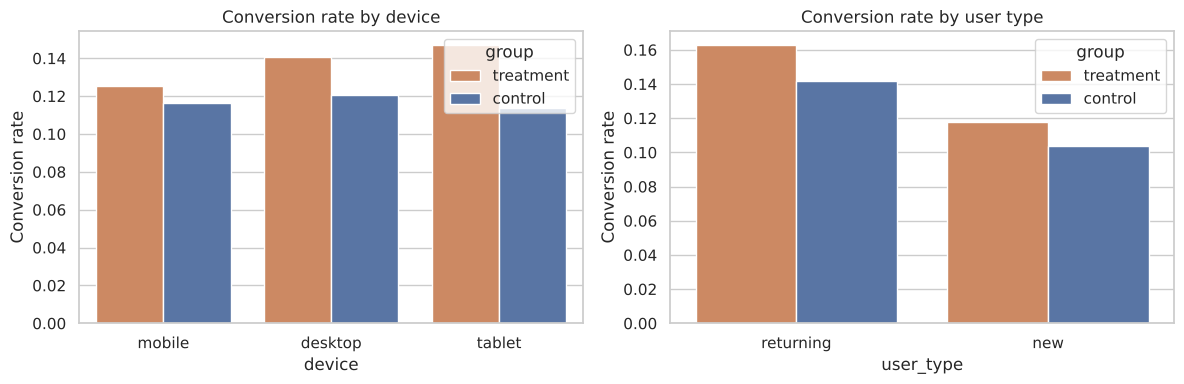

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=df, x="device", y="converted", hue="group", palette=COLORS,
            order=["mobile", "desktop", "tablet"], errorbar=None, ax=ax[0])
ax[0].set_title("Conversion rate by device")
ax[0].set_ylabel("Conversion rate")

sns.barplot(data=df, x="user_type", y="converted", hue="group", palette=COLORS,
            errorbar=None, ax=ax[1])
ax[1].set_title("Conversion rate by user type")
ax[1].set_ylabel("Conversion rate")

plt.tight_layout()
plt.savefig("figures/02_conversion_by_segment.png", dpi=150)
plt.show()

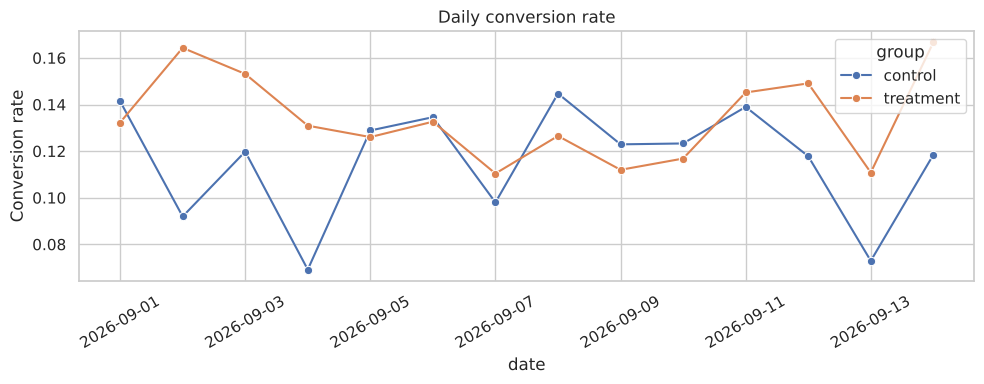

In [9]:
daily = df.groupby(["date", "group"])["converted"].mean().reset_index()

plt.figure(figsize=(10, 4))
sns.lineplot(data=daily, x="date", y="converted", hue="group", palette=COLORS, marker="o")
plt.title("Daily conversion rate")
plt.ylabel("Conversion rate")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("figures/03_daily_conversion.png", dpi=150)
plt.show()

/tmp/ipykernel_194/3469517508.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=buyers, x="group", y="revenue_capped", palette=COLORS, ax=ax[1])


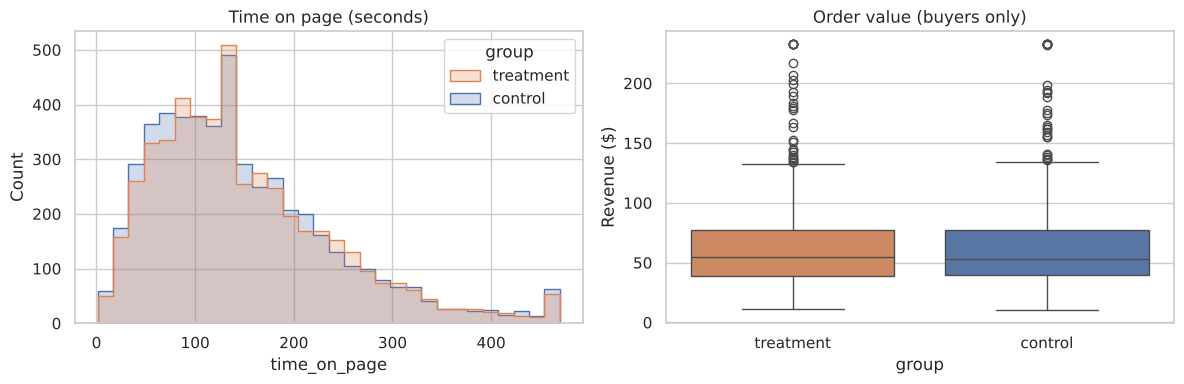

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="time_on_page", hue="group", palette=COLORS,
             bins=30, element="step", ax=ax[0])
ax[0].set_title("Time on page (seconds)")

buyers = df[df["converted"] == 1]
sns.boxplot(data=buyers, x="group", y="revenue_capped", palette=COLORS, ax=ax[1])
ax[1].set_title("Order value (buyers only)")
ax[1].set_ylabel("Revenue ($)")

plt.tight_layout()
plt.savefig("figures/04_distributions.png", dpi=150)
plt.show()

**Observations:** Treatment converts at a higher rate than control overall. The daily lines overlap considerably, so the difference is modest. Returning users convert more than new users in both groups. A hypothesis test is needed to determine whether the gap exceeds what random variation would produce.

## 5. Hypothesis Testing

### 5.1 Check that the groups are balanced
Users were randomly split, so group sizes should be close to 50/50.

In [11]:
control = df[df["group"] == "control"]
treatment = df[df["group"] == "treatment"]

n_c, n_t = len(control), len(treatment)
x_c, x_t = control["converted"].sum(), treatment["converted"].sum()
p_c, p_t = x_c / n_c, x_t / n_t

print(f"Control:   {n_c:,} users, {x_c:,} conversions, rate = {p_c:.2%}")
print(f"Treatment: {n_t:,} users, {x_t:,} conversions, rate = {p_t:.2%}")

# chi-square goodness-of-fit against a 50/50 split
chi2_split, p_split = stats.chisquare([n_c, n_t])
print(f"\nSplit check p-value = {p_split:.3f}  ->  "
      f"{'groups are balanced' if p_split > 0.05 else 'groups look unbalanced'}")

Control:   5,061 users, 593 conversions, rate = 11.72%
Treatment: 4,939 users, 661 conversions, rate = 13.38%

Split check p-value = 0.222  ->  groups are balanced


### 5.2 Two-proportion z-test (primary metric)

The conversion rate is a proportion, so we compare the two proportions:

$$z = \frac{\hat p_t - \hat p_c}{\sqrt{\hat p (1-\hat p)\left(\frac{1}{n_t}+\frac{1}{n_c}\right)}}$$

where $\hat p$ is the overall (pooled) conversion rate.

In [12]:
# pooled proportion and standard error
p_pool = (x_c + x_t) / (n_c + n_t)
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_c + 1 / n_t))

z = (p_t - p_c) / se_pool
p_value = 2 * (1 - stats.norm.cdf(abs(z)))        # two-sided

# 95% confidence interval for the difference
diff = p_t - p_c
se_diff = np.sqrt(p_c * (1 - p_c) / n_c + p_t * (1 - p_t) / n_t)
ci_low, ci_high = diff - 1.96 * se_diff, diff + 1.96 * se_diff

print(f"Difference in conversion rate: {diff*100:+.2f} percentage points")
print(f"Relative lift:                 {diff / p_c:+.1%}")
print(f"z-statistic:                   {z:.3f}")
print(f"p-value:                       {p_value:.4f}")
print(f"95% confidence interval:       [{ci_low*100:+.2f}, {ci_high*100:+.2f}] percentage points")
print()
print("Reject H0 (significant)" if p_value < ALPHA else "Fail to reject H0 (not significant)")

Difference in conversion rate: +1.67 percentage points
Relative lift:                 +14.2%
z-statistic:                   2.515
p-value:                       0.0119
95% confidence interval:       [+0.37, +2.97] percentage points

Reject H0 (significant)


In [13]:
# cross-check with a chi-square test of independence
table = pd.crosstab(df["group"], df["converted"])
chi2, p_chi, dof, expected = stats.chi2_contingency(table, correction=False)
print(table, "\n")
print(f"Chi-square p-value = {p_chi:.4f}  (matches the z-test p-value of {p_value:.4f})")

converted     0    1
group               
control    4468  593
treatment  4278  661 

Chi-square p-value = 0.0119  (matches the z-test p-value of 0.0119)


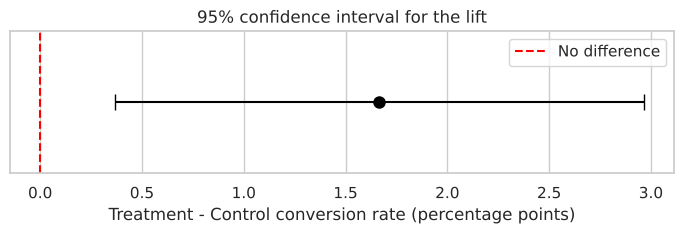

In [14]:
# visualize the confidence interval
plt.figure(figsize=(7, 2.5))
plt.errorbar(diff * 100, 0, xerr=[[(diff - ci_low) * 100], [(ci_high - diff) * 100]],
             fmt="o", color="black", capsize=6, markersize=8)
plt.axvline(0, color="red", linestyle="--", label="No difference")
plt.yticks([])
plt.xlabel("Treatment - Control conversion rate (percentage points)")
plt.title("95% confidence interval for the lift")
plt.legend()
plt.tight_layout()
plt.savefig("figures/05_confidence_interval.png", dpi=150)
plt.show()

### 5.3 Revenue per user (secondary metric)

Revenue per user is continuous, so Welch's t-test is used (it does not assume equal variances).

In [15]:
t_stat, p_rev = stats.ttest_ind(treatment["revenue_capped"], control["revenue_capped"], equal_var=False)

mean_c, mean_t = control["revenue_capped"].mean(), treatment["revenue_capped"].mean()
print(f"Revenue per user: control ${mean_c:.2f} vs treatment ${mean_t:.2f}  (difference ${mean_t - mean_c:+.2f})")
print(f"t-statistic = {t_stat:.3f}, p-value = {p_rev:.4f}")
print("Significant" if p_rev < ALPHA else "Not significant at alpha = 0.05")

# is the revenue difference just more buyers, or bigger orders?
avg_order_c = control.loc[control["converted"] == 1, "revenue_capped"].mean()
avg_order_t = treatment.loc[treatment["converted"] == 1, "revenue_capped"].mean()
print(f"\nAverage order value (buyers only): control ${avg_order_c:.2f} vs treatment ${avg_order_t:.2f}")

Revenue per user: control $7.43 vs treatment $8.44  (difference $+1.01)
t-statistic = 2.054, p-value = 0.0400
Significant



Average order value (buyers only): control $63.40 vs treatment $63.08


### 5.4 Does the effect differ by device? (exploratory)
Splitting by segment reduces sample sizes, so these results are less reliable. Treat them as hypotheses for follow-up tests, not conclusions.

In [16]:
rows = []
for device, seg in df[df["device"] != "unknown"].groupby("device"):
    c, t = seg[seg["group"] == "control"], seg[seg["group"] == "treatment"]
    pc, pt = c["converted"].mean(), t["converted"].mean()
    pp = (c["converted"].sum() + t["converted"].sum()) / (len(c) + len(t))
    zz = (pt - pc) / np.sqrt(pp * (1 - pp) * (1 / len(c) + 1 / len(t)))
    rows.append({"device": device, "control_rate": pc, "treatment_rate": pt,
                 "lift_pp": (pt - pc) * 100, "p_value": 2 * (1 - stats.norm.cdf(abs(zz)))})

pd.DataFrame(rows)

,device,control_rate,treatment_rate,lift_pp,p_value
0,desktop,0.120,0.141,2.007,0.072
1,mobile,0.116,0.126,0.904,0.315
2,tablet,0.114,0.147,3.331,0.162


## 6. Conclusion

**Results**

- **Conversion:** 13.38% (treatment) vs 11.72% (control), a lift of 1.67 percentage points (14.2% relative).
- **Significance:** z = 2.52, p = 0.012. Since p < 0.05, reject H0. The 95% confidence interval for the lift is [+0.37, +2.97] percentage points. It excludes 0 but is wide, so the true effect could be small or moderately large.
- **Revenue:** revenue per user increased from $7.43 to $8.44 (p = 0.040). Average order value is nearly unchanged (about $63), so the increase comes from more buyers rather than larger orders.
- **Segments (exploratory):** treatment was higher on desktop, mobile and tablet, but no single-device difference was significant on its own.

**Recommendation:** Roll out the redesigned checkout page. The conversion lift is statistically significant and revenue per user increased.

**Limitations**
- The revenue p-value (0.040) is close to the 0.05 threshold and should be treated as supporting evidence only.
- The test ran for 14 days. A longer test would show whether the lift persists beyond any novelty effect.
- Capping outliers and median imputation are analyst judgment calls. The conversion test is not affected by them, since it uses only the 0/1 outcome.
- The data is simulated for this project, so real-world results would differ.

**Next steps:** Extend the test to narrow the confidence interval, and test a mobile-specific checkout design, since mobile showed the smallest lift.